# Lab 4 — Leakage-safe Classification & Regression

**Problem framing**
- **A (classification):** predict whether a support ticket is `escalated` (0/1).
- **B (regression):** predict `resolution_time_hours`.

`ticket_id` is just an identifier, so it is dropped in both experiments.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.metrics import classification_report, confusion_matrix, mean_absolute_error, mean_squared_error

clf_df = pd.read_csv("data/classification_escalation.csv")
reg_df = pd.read_csv("data/resolution_time_regression.csv")
display(clf_df.head(), reg_df.head())
print("Missing values:\n", clf_df.isna().sum())
print("\nEscalated share:", round(clf_df["escalated"].mean(), 3))

,ticket_id,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,T0000,2.0,15.0,Medium,Email,61.818896,0
1,T0001,9.0,6.0,Critical,Chat,110.024317,0
2,T0002,10.0,8.0,High,Phone,36.311244,0
3,T0003,2.0,1.0,Medium,Phone,85.127855,0
4,T0004,8.0,14.0,Medium,Chat,18.225059,0


,ticket_id,complexity_score,team_experience_years,priority,channel,customer_tenure_months,resolution_time_hours
0,R0000,7.0,10.0,Medium,Chat,32.638377,8.38724
1,R0001,4.0,15.0,Medium,Chat,45.273760,0.50000
2,R0002,4.0,13.0,Low,Portal,44.878323,0.50000
3,R0003,1.0,10.0,High,Phone,40.095034,0.50000
4,R0004,3.0,15.0,Low,Portal,47.451134,0.50000


Missing values:
 ticket_id                  0
complexity_score          22
team_experience_years     36
priority                  13
channel                    9
customer_tenure_months    31
escalated                  0
dtype: int64

Escalated share: 0.212


## Preprocessing (inside a Pipeline)
- **Numeric:** median imputation (robust to outliers) + scaling (needed by k-NN, logistic and ridge regression).
- **Categorical:** most-frequent imputation + one-hot encoding.
- Because this is inside the `Pipeline`, it is learned **only from the training folds**, so no information leaks from validation or test data.

In [2]:
num_cols = ["complexity_score", "team_experience_years", "customer_tenure_months"]
cat_cols = ["priority", "channel"]

def make_pipe(model):
    prep = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])
    return Pipeline([("prep", prep), ("model", model)])

---
# Experiment A — Classification
Stratified 80/20 split (only ~21% are escalated), then 5-fold `StratifiedKFold` with **F1** as the main metric. Accuracy would be misleading on imbalanced classes.

,model,F1 mean,F1 std
0,Logistic Regression,0.393,0.063
1,k-NN,0.361,0.050
2,Decision Tree,0.331,0.058


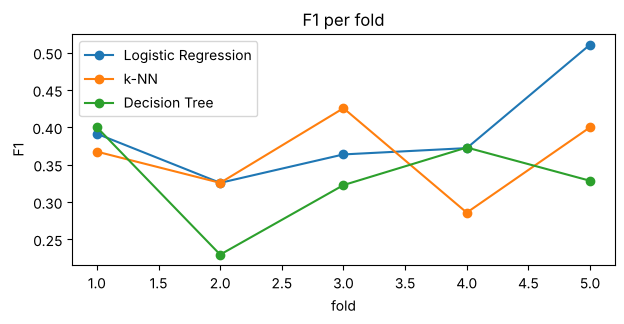

In [3]:
X = clf_df.drop(columns=["ticket_id", "escalated"]); y = clf_df["escalated"]
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
cv_a = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models_a = {"Logistic Regression": LogisticRegression(max_iter=1000),
            "k-NN": KNeighborsClassifier(),
            "Decision Tree": DecisionTreeClassifier(random_state=42)}
rows, folds = [], {}
for name, m in models_a.items():
    f1 = cross_validate(make_pipe(m), Xa_tr, ya_tr, cv=cv_a, scoring="f1")["test_score"]
    folds[name] = f1
    rows.append({"model": name, "F1 mean": f1.mean(), "F1 std": f1.std()})
display(pd.DataFrame(rows).round(3))

pd.DataFrame(folds, index=range(1, 6)).plot(marker="o", figsize=(7, 3), title="F1 per fold")
plt.xlabel("fold"); plt.ylabel("F1")

**Fold variability:** F1 changes a lot from fold to fold (for logistic regression, 0.33–0.51), and the ranking of the models changes between folds. Small differences between models are therefore not reliable.

### Tuning (GridSearchCV, same folds, F1)
- Logistic Regression: `C` ∈ {0.01, 0.1, 1, 10}, `class_weight` ∈ {None, balanced}
- Decision Tree: `max_depth` ∈ {2–8, None}, `min_samples_leaf` ∈ {1, 5, 10, 20}, `class_weight` ∈ {None, balanced}

In [4]:
grids_a = {
    "Logistic Regression": (LogisticRegression(max_iter=1000),
        {"model__C": [0.01, 0.1, 1, 10], "model__class_weight": [None, "balanced"]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=42),
        {"model__max_depth": [2, 3, 4, 5, 6, 8, None], "model__min_samples_leaf": [1, 5, 10, 20],
         "model__class_weight": [None, "balanced"]})}
search_a = {}
for name, (m, grid) in grids_a.items():
    gs = GridSearchCV(make_pipe(m), grid, cv=cv_a, scoring="f1").fit(Xa_tr, ya_tr)
    search_a[name] = gs
    print(f"{name}: F1 = {gs.best_score_:.3f} ± {gs.cv_results_['std_test_score'][gs.best_index_]:.3f}  {gs.best_params_}")

Logistic Regression: F1 = 0.520 ± 0.042  {'model__C': 0.1, 'model__class_weight': 'balanced'}
Decision Tree: F1 = 0.498 ± 0.045  {'model__class_weight': 'balanced', 'model__max_depth': 4, 'model__min_samples_leaf': 20}


**Chosen model: tuned Logistic Regression** (C=0.1, balanced). It has the highest CV F1 (0.52) and the lowest fold variation, and it is easy to interpret.

In [5]:
# Test set — evaluated ONCE
pred = search_a["Logistic Regression"].predict(Xa_te)
print(classification_report(ya_te, pred, digits=3))
print("Confusion matrix [[TN FP] [FN TP]]:\n", confusion_matrix(ya_te, pred))

              precision    recall  f1-score   support

           0      0.914     0.824     0.867       142
           1      0.519     0.711     0.600        38

    accuracy                          0.800       180
   macro avg      0.717     0.767     0.733       180
weighted avg      0.831     0.800     0.810       180

Confusion matrix [[TN FP] [FN TP]]:
 [[117  25]
 [ 11  27]]


**Test F1 = 0.60** (recall 0.71, precision 0.52).
- **False negatives (11):** escalations the model missed. These are the costly errors, because the problem is not caught early.
- **False positives (25):** false alarms. They waste some staff time but are cheaper. Balanced class weights deliberately accept more of these in order to catch more escalations.

---
# Experiment B — Regression
80/20 split, 5-fold `KFold`, **MAE** as the main metric (RMSE also shown).

In [6]:
X = reg_df.drop(columns=["ticket_id", "resolution_time_hours"]); y = reg_df["resolution_time_hours"]
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(X, y, test_size=0.2, random_state=42)
cv_b = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"}

models_b = {"Linear Regression": LinearRegression(), "Ridge": Ridge(),
            "Decision Tree": DecisionTreeRegressor(random_state=42)}
rows = []
for name, m in models_b.items():
    r = cross_validate(make_pipe(m), Xb_tr, yb_tr, cv=cv_b, scoring=scoring)
    rows.append({"model": name, "MAE mean": -r["test_MAE"].mean(), "MAE std": r["test_MAE"].std(),
                 "RMSE mean": -r["test_RMSE"].mean()})
display(pd.DataFrame(rows).round(3))

,model,MAE mean,MAE std,RMSE mean
0,Linear Regression,2.035,0.172,2.961
1,Ridge,2.035,0.171,2.960
2,Decision Tree,3.239,0.054,4.588


### Tuning: Ridge `alpha` (0.001–1000) and tree `max_depth` / `min_samples_leaf`

In [7]:
grids_b = {
    "Ridge": (Ridge(), {"model__alpha": np.logspace(-3, 3, 13)}),
    "Decision Tree": (DecisionTreeRegressor(random_state=42),
        {"model__max_depth": [2, 3, 4, 5, 6, 8, 10, None], "model__min_samples_leaf": [1, 5, 10, 20, 40]})}
search_b = {}
for name, (m, grid) in grids_b.items():
    gs = GridSearchCV(make_pipe(m), grid, cv=cv_b, scoring=scoring, refit="MAE").fit(Xb_tr, yb_tr)
    search_b[name] = gs
    i = gs.best_index_
    print(f"{name}: MAE = {-gs.best_score_:.3f} ± {gs.cv_results_['std_test_MAE'][i]:.3f}  {gs.best_params_}")

Ridge: MAE = 2.035 ± 0.172  {'model__alpha': np.float64(0.31622776601683794)}
Decision Tree: MAE = 2.364 ± 0.089  {'model__max_depth': 6, 'model__min_samples_leaf': 20}


**Chosen model: tuned Ridge** (alpha ≈ 0.32). It has the lowest CV MAE (2.04 h) and is stable and simple. The best tree only reaches 2.36 h.

Test MAE : 2.23 h
Test RMSE: 3.40 h

5 worst tickets cause 57% of squared error but only 18% of absolute error


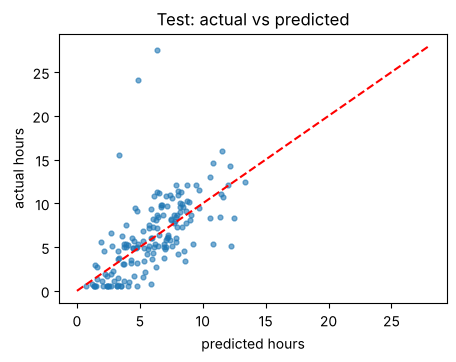

In [8]:
# Test set — evaluated ONCE
pred = search_b["Ridge"].predict(Xb_te)
resid = yb_te - pred
print(f"Test MAE : {mean_absolute_error(yb_te, pred):.2f} h")
print(f"Test RMSE: {np.sqrt(mean_squared_error(yb_te, pred)):.2f} h")

worst5 = resid.abs().nlargest(5).index
print(f"\n5 worst tickets cause {100*(resid[worst5]**2).sum()/(resid**2).sum():.0f}% of squared error "
      f"but only {100*resid[worst5].abs().sum()/resid.abs().sum():.0f}% of absolute error")

plt.figure(figsize=(5, 3.5)); plt.scatter(pred, yb_te, s=12, alpha=0.6)
plt.plot([0, 28], [0, 28], "r--"); plt.xlabel("predicted hours"); plt.ylabel("actual hours")
plt.title("Test: actual vs predicted")

**Test MAE = 2.23 h**, RMSE = 3.40 h.

**Outliers and MAE vs RMSE:** a few very long tickets (up to 27 h) sit far from the line. RMSE squares the errors, so these few tickets dominate it (57%), while they cause only 18% of MAE. As a result, **RMSE prefers models that avoid big misses**, while **MAE prefers models that are accurate on typical tickets**, so the two metrics can choose different models.

---
# Report summary

| | Model | CV (mean ± std) | Test |
|---|---|---|---|
| A | **Logistic Regression (tuned)** | F1 0.520 ± 0.042 | F1 0.600 |
| A | Decision Tree (tuned) | F1 0.498 ± 0.045 | – |
| B | **Ridge (tuned)** | MAE 2.04 ± 0.17 h | MAE 2.23 h |
| B | Decision Tree (tuned) | MAE 2.36 ± 0.09 h | – |

**Leakage prevention:** all preprocessing is inside the Pipeline, the test set is split off first and used only once, and `ticket_id` and the target are never used as features.

**Limitations:** the dataset is small, there are only 5 features, the regression target is skewed with outliers, and the classification threshold was left at 0.5.

## Reflections
1. **Why stratify?** It keeps the same escalation rate (~21%) in train and test, so the scores are fair and stable.
2. **Why preprocessing inside the pipeline?** So imputers and scalers learn only from training data. Otherwise test information leaks in and the scores are too optimistic.
3. **What does fold variability tell us?** How stable a model is, and that small differences between models may just be noise.
4. **Why evaluate the test set only once?** Using it repeatedly means tuning on it, so the final score is no longer an honest estimate.
5. **Deployment constraints:** the need for interpretability, prediction speed (k-NN is slow), the cost of false negatives versus false positives, or new and changing data could change the choice of model.